In [5]:
import cv2 as cv
import numpy as np
from sklearn.svm import LinearSVC
from skimage.feature import hog
import pickle
from copy import deepcopy

import os
import re
import json
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Tuple, List, Optional

import numpy as np
import cv2

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from skimage.feature import hog

# EX 1

## Preprocesare date

In [13]:

def mirror_images(images):
    new_images = []

    for image in images:
        image = cv.flip(image, 1)
        new_images.append(image)

    return new_images

SHAPE = (200,200)
num_images_class = 55
num_train = 40
num_test = 15

data_dir = "./Lucrare2/data/ex1"
file_names = sorted(os.listdir("./Lucrare2/data/ex1"))

file_paths = [os.path.join(data_dir,file_name) for file_name in file_names]
images = []

# datele vor fi redimensionate in forma de patrat
for file_path in file_paths:
    img = cv.imread(file_path)
    img = cv.resize(img,SHAPE)
    images.append(img)

images_deedee = images[:num_images_class]
images_louie = images[num_images_class: 2 * num_images_class]
images_dexter = images[2 * num_images_class: 3 * num_images_class]
images_tommy = images[3 * num_images_class: ]

# datele de antrenare sunt augmentate, prin flip
images_deedee_train = images_deedee[:num_train] + mirror_images(images_deedee[:num_train])
images_louie_train = images_louie[:num_train] + mirror_images(images_louie[:num_train])
images_dexter_train = images_dexter[:num_train] + mirror_images(images_dexter[:num_train])
images_tommy_train = images_tommy[:num_train] + mirror_images(images_tommy[:num_train])

images_deedee_test = images_deedee[-num_test:]
images_louie_test = images_louie[-num_test:]
images_dexter_test = images_dexter[-num_test:]
images_tommy_test = images_tommy[-num_test:]


error: OpenCV(4.7.0) D:\bld\libopencv_1675730119851\work\modules\imgproc\src\resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'cv::resize'


# Descriptori HOG

In [ ]:

HOG_CELL_SHAPE = (8,8)
HOG_BLOCK_SHAPE = (2,2)
HOG_NUM_BINS = 9
THRESHOLD = 0.0

def get_descriptors(images):

    descriptors = []

    for image in tqdm(images):
        image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
        features = hog(image,
                       orientations=HOG_NUM_BINS,
                       pixels_per_cell=HOG_CELL_SHAPE,
                       cells_per_block=HOG_BLOCK_SHAPE,)

        descriptors.append(features)

    return np.array(descriptors)



features_deedee_train = get_descriptors(images_deedee_train)
features_louie_train = get_descriptors(images_louie_train)
features_dexter_train = get_descriptors(images_dexter_train)
features_tommy_train = get_descriptors(images_tommy_train)

features_deedee_test = get_descriptors(images_deedee_test)
features_louie_test = get_descriptors(images_louie_test)
features_dexter_test = get_descriptors(images_dexter_test)
features_tommy_test = get_descriptors(images_tommy_test)


100%|██████████| 15/15 [00:00<00:00, 48.39it/s]


# Linear SVC pentru clasificare

100%|██████████| 2/2 [00:00<00:00,  2.93it/s]


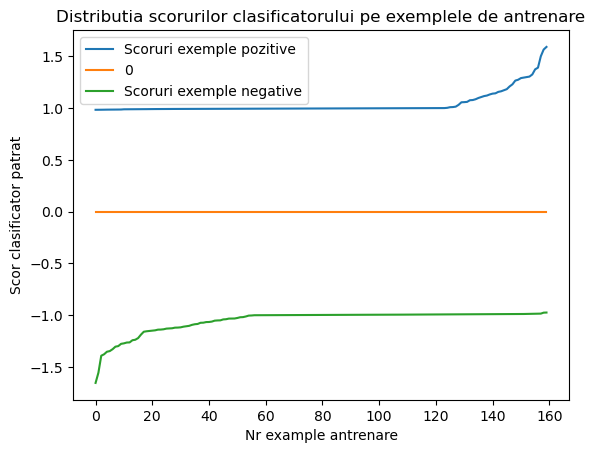

In [ ]:
def train_classifier(training_examples, training_labels) -> LinearSVC:
        best_accuracy = 0
        best_model = None

        Cs = [10 ** -1,10 ** 0]

        for C in tqdm(Cs):
            model = LinearSVC(C=C)
            model.fit(training_examples, training_labels)
            current_accuracy = model.score(training_examples, training_labels)

            if current_accuracy > best_accuracy:
                best_accuracy = current_accuracy
                best_model = deepcopy(model)


        scores = best_model.decision_function(training_examples)
        positive_scores = scores[training_labels > 0]
        negative_scores = scores[training_labels <= 0]


        plt.plot(np.sort(positive_scores))
        plt.plot(np.zeros(len(positive_scores)))
        plt.plot(np.sort(negative_scores))
        plt.xlabel('Nr example antrenare')
        plt.ylabel('Scor clasificator patrat')
        plt.title('Distributia scorurilor clasificatorului pe exemplele de antrenare')
        plt.legend(['Scoruri exemple pozitive', '0', 'Scoruri exemple negative'])
        plt.show()

        return best_model


positives = np.concatenate((features_deedee_train, features_dexter_train))
negatives = np.concatenate((features_louie_train, features_tommy_train))

training_examples = np.concatenate((positives, negatives))
training_labels = np.array([1] * len(positives) + [0] * len(negatives))


model = train_classifier(training_examples, training_labels)


# Testare
Clasa 1 -> pentru personaje din dexter

Clasa 3 -> pentru personaje din louie

In [ ]:
# Se pun laolalta toti descriptorii de test si se apeleaza predict pe model
test_descriptors = np.concatenate((features_deedee_test, features_dexter_test,features_louie_test, features_tommy_test))
expected_positives = np.array([1] * (len(test_descriptors) // 2))
expected_negatives = np.array([0] * (len(test_descriptors) // 2))
expected_labels = np.concatenate((expected_positives, expected_negatives))

num_expected = len(expected_labels)

predictions = model.predict(test_descriptors)
#Se calculeaza cate predictii din cele 60 sunt corecte
num_positive_predictions = np.sum(expected_labels == predictions)

accuracy = num_positive_predictions / num_expected

print(accuracy)


0.95


# Ex 2